# Portfolio Optimization with Mean-Variance Analysis

This project builds a diversified portfolio of 8 ETFs (equities, bonds, gold, real estate) using modern portfolio theory. Status: in progress.

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

## Data: adjusted daily closing prices for 8 ETFs (2015-2025)

In [12]:
tickers = ["SPY", "EFA", "EEM", "IEF", "TLT", "LQD", "GLD", "VNQ"]
start_date = "2015-01-01"
end_date = "2026-01-01"
data = yf.download(tickers, start=start_date, end=end_date, auto_adjust=True)
prices = data["Close"]
prices.head()

[*********************100%***********************]  8 of 8 completed


Ticker,EEM,EFA,GLD,IEF,LQD,SPY,TLT,VNQ
Date,,,,,,,,
2015-01-02,30.198088,43.098610,114.080002,81.462914,79.104065,169.267548,91.566444,51.642838
2015-01-05,29.660648,42.081272,115.800003,81.960007,79.427521,166.210587,93.004860,51.925514
2015-01-06,29.536024,41.604614,117.120003,82.510567,79.751022,164.645065,94.680534,52.440544
2015-01-07,30.174732,42.067043,116.430000,82.495255,79.856644,166.696747,94.493538,53.244514
2015-01-08,30.688799,42.636185,115.940002,82.158783,79.599197,169.654785,93.242111,53.445488


In [13]:
# Data checks: dimensions, missing values, first and last dates
print(prices.shape)
print(prices.isna().sum())
print(prices.index[0], prices.index[-1])

(2766, 8)
Ticker
EEM    0
EFA    0
GLD    0
IEF    0
LQD    0
SPY    0
TLT    0
VNQ    0
dtype: int64
2015-01-02 00:00:00 2025-12-31 00:00:00


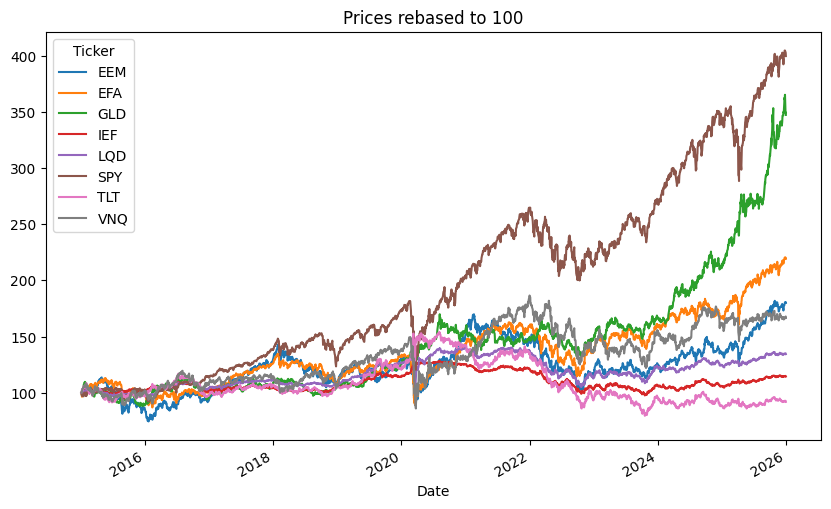

In [14]:
prices_base100 = prices / prices.iloc[0] * 100
prices_base100.plot(figsize=(10,6), title="Prices rebased to 100")
plt.show()

## Step 1: Daily returns and annualized statistics

In [15]:
# Daily simple return: (today's price - yesterday's price) / yesterday's price
returns = prices.pct_change()

# The first day has no previous price, so its row is empty (NaN): drop it
returns = returns.dropna()

print(returns.shape)
returns.head()

(2765, 8)


Ticker,EEM,EFA,GLD,IEF,LQD,SPY,TLT,VNQ
Date,,,,,,,,
2015-01-05,-0.017797,-0.023605,0.015077,0.006102,0.004089,-0.018060,0.015709,0.005474
2015-01-06,-0.004202,-0.011327,0.011399,0.006717,0.004073,-0.009419,0.018017,0.009919
2015-01-07,0.021625,0.011115,-0.005891,-0.000186,0.001324,0.012461,-0.001975,0.015331
2015-01-08,0.017036,0.013529,-0.004209,-0.004079,-0.003224,0.017745,-0.013244,0.003775
2015-01-09,-0.003299,-0.004839,0.011385,0.004934,0.002654,-0.008014,0.010953,0.000470


In [16]:
trading_days = 252  # approximate number of trading days in a year

# Annualize the mean daily return and the daily volatility
mean_annual = returns.mean() * trading_days
vol_annual = returns.std() * np.sqrt(trading_days)

stats = pd.DataFrame({"Annual return": mean_annual,
                      "Annual volatility": vol_annual})
stats.round(4)

,Annual return,Annual volatility
Ticker,,
EEM,0.0746,0.2042
EFA,0.0865,0.1721
GLD,0.1244,0.1475
IEF,0.0146,0.0663
LQD,0.0306,0.0845
SPY,0.1422,0.1779
TLT,0.0037,0.1504
VNQ,0.0678,0.2051


### Interpretation

Over 2015-2025, risk and return are not aligned across the eight ETFs. VNQ (US real estate) is the most volatile asset (20.5%) but returns only 6.8% per year, while SPY (US equities) returns 14.2% with lower volatility (17.8%). Taking more risk was not rewarded.

The bond ETFs illustrate interest rate risk. IEF (7-10 year Treasuries) is the least volatile asset (6.6%), whereas TLT (20+ year Treasuries) shows a volatility close to equities (15.0%) for an almost zero return (0.4%). When the Federal Reserve raised rates sharply in 2022, bond prices fell, and long-maturity bonds fell the most because of their higher duration.

Volatility alone is therefore not enough to compare assets. Return must be measured per unit of risk, and the way assets move together must be analysed, since this drives portfolio risk (Step 2: covariance and correlation).

Note: annual returns are arithmetic means of daily returns multiplied by 252.

In [17]:
# Return per unit of risk: how much return each asset delivers for 1% of volatility
stats["Return / Volatility"] = mean_annual / vol_annual
stats.round(4)

,Annual return,Annual volatility,Return / Volatility
Ticker,,,
EEM,0.0746,0.2042,0.3655
EFA,0.0865,0.1721,0.5026
GLD,0.1244,0.1475,0.8436
IEF,0.0146,0.0663,0.2200
LQD,0.0306,0.0845,0.3616
SPY,0.1422,0.1779,0.7991
TLT,0.0037,0.1504,0.0245
VNQ,0.0678,0.2051,0.3305


In [18]:
# Rank assets by return per unit of risk, from best to worst
stats_sorted = stats.sort_values("Return / Volatility", ascending=False)
stats_sorted.round(4)

,Annual return,Annual volatility,Return / Volatility
Ticker,,,
GLD,0.1244,0.1475,0.8436
SPY,0.1422,0.1779,0.7991
EFA,0.0865,0.1721,0.5026
EEM,0.0746,0.2042,0.3655
LQD,0.0306,0.0845,0.3616
VNQ,0.0678,0.2051,0.3305
IEF,0.0146,0.0663,0.2200
TLT,0.0037,0.1504,0.0245


GLD has the best return per unit of risk (0.84) and TLT the worst (0.02). This changes the ranking based on returns alone: SPY loses first place to gold, which achieves a slightly lower return with lower volatility. EEM and LQD have almost the same ratio (0.37 and 0.36), although EEM is more than twice as risky as LQD.

This gap reflects two differences. First, LQD holds investment-grade US corporate bonds: bondholders receive fixed coupons and are repaid before shareholders in case of bankruptcy, while EEM holds equities, which absorb losses first. Second, emerging markets carry specific risks: political instability, currency depreciation against the US dollar, and a strong dependence on foreign capital, which tends to leave when US interest rates rise, making it harder and more expensive for local companies to refinance their debt.